# Comparación base y alternativa de VOC

Esta libreta lee dos ejecuciones guardadas del CLI. No ajusta modelos ni consulta un LLM.
La muestra se fijó antes del filtro, por plataforma y mes (julio–agosto de 2026), semilla 42.
Ambos sistemas usan UMAP 5D, HDBSCAN `eom` y KeyBERTInspired + MMR.
Base usa Robertuito original; alternativa aplica el SVM social y tiendas v3 a todas las fuentes.

Las distribuciones son predicciones, no métricas de exactitud. No conocemos los IDs del entrenamiento de sentimiento.
La transferencia de tiendas v3 a fuentes sociales no tiene aquí una referencia independiente.

In [1]:
import json
from pathlib import Path
from dataclasses import asdict
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from voc.analysis.store import read_analysis
from voc.datasets.manifest import file_hash
from voc_ml.experiments.operations import load_protocol
from voc.paths import data_root

ROOT = data_root() / "experiments/julaug-2026"
protocol = load_protocol(ROOT)
runs = {s: json.loads((ROOT / f"{s}-run.json").read_text()) for s in ("base", "alternative")}
assert all(r["state"] == "completed" for r in runs.values())
analyses = {s: read_analysis(r["representation"]["analysis_id"]) for s, r in runs.items()}
frames = {}
for s, saved in analyses.items():
    sentiment = pd.DataFrame([asdict(x) for x in saved.sentiments])
    assignments = pd.DataFrame([asdict(x) for x in saved.assignments])
    frames[s] = saved.reviews.merge(sentiment, on="record_id", validate="one_to_one").merge(assignments, on="record_id", validate="one_to_one")
    assert len(frames[s]) == saved.manifest.coverage["selected_reviews"]
    assert runs[s]["representation"]["tracking_verified"]
    assert frames[s].status.eq("classified").all()
verdict = pd.read_csv(ROOT / "relevance.csv")
assert set(frames["base"].record_id) == set(verdict.record_id)
assert set(frames["alternative"].record_id) == set(verdict.loc[verdict.keep, "record_id"])
paired = frames["base"][["record_id", "model_text", "model_label", "platform"]].merge(frames["alternative"][["record_id", "model_text", "model_label"]], on="record_id", suffixes=("_base", "_alternative"), validate="one_to_one")
assert paired.model_text_base.equals(paired.model_text_alternative)
print("Protocolo:", protocol["protocol_id"])
print("Intersección verificada:", len(paired))

Protocolo: 9c226c3c1b26b1382c5859024b85b3c5b0692319dcc9bf2f9b6a9c79d8672a53
Intersección verificada: 987


## Cobertura y retención

La asignación proporcional conserva las proporciones de la población elegible, con pocos casos de YouTube.
Las exclusiones son decisiones automáticas del SVM; no se consideran irrelevantes confirmados por una persona.

In [2]:
retention = verdict.groupby("platform").agg(initial=("keep", "size"), retained=("keep", "sum"))
retention["removed"] = retention.initial - retention.retained
display(retention)
rows = []
for s, saved in analyses.items():
    rows.append({"system": s, **saved.manifest.coverage, "wall_seconds": runs[s]["wall_seconds"]})
display(pd.DataFrame(rows))

,initial,retained,removed
platform,,,
app_store,49,49,0
google_play,876,876,0
x,64,62,2
youtube,11,0,11


,system,assigned_reviews,classified,excluded,failed,selected_reviews,topic_count,unassigned_reviews,wall_seconds
0,base,953,1000,0,0,1000,18,47,51.426846
1,alternative,846,987,0,0,987,28,141,45.183917


## Sentimiento sobre los mismos textos

La tabla cruza predicciones sobre la intersección. No es una matriz de confusión: ninguno de sus ejes es una etiqueta humana.
Los porcentajes de la figura comparten denominador. Un cambio de etiqueta no equivale a una corrección.

model_label_alternative,negative,neutral,positive
model_label_base,,,
negative,384,43,39
neutral,25,4,207
positive,0,0,285


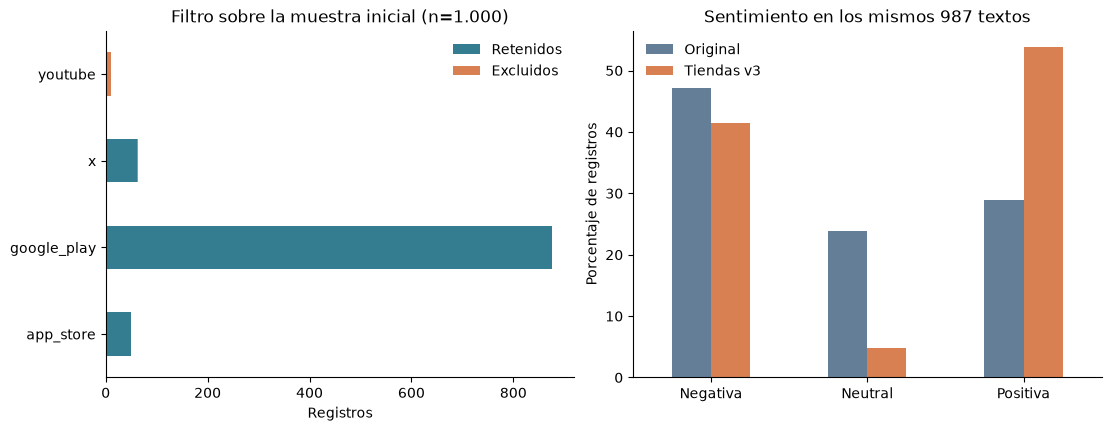

In [3]:
labels = ["negative", "neutral", "positive"]
transitions = pd.crosstab(paired.model_label_base, paired.model_label_alternative).reindex(index=labels, columns=labels, fill_value=0)
common_counts = pd.DataFrame({"Original": paired.model_label_base.value_counts(), "Tiendas v3": paired.model_label_alternative.value_counts()}).reindex(labels, fill_value=0)
assert int(transitions.to_numpy().sum()) == len(paired)
assert common_counts.sum().eq(len(paired)).all()
display(transitions)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
retention[["retained", "removed"]].rename(columns={"retained":"Retenidos", "removed":"Excluidos"}).plot.barh(stacked=True, ax=axes[0], color=["#347d91", "#d88052"])
axes[0].set(xlabel="Registros", ylabel="", title="Filtro sobre la muestra inicial (n=1.000)")
(common_counts / len(paired) * 100).rename(index={"negative":"Negativa", "neutral":"Neutral", "positive":"Positiva"}).plot.bar(ax=axes[1], color=["#657e98", "#d88052"], rot=0)
axes[1].set(ylabel="Porcentaje de registros", xlabel="", title=f"Sentimiento en los mismos {len(paired)} textos")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
plt.show()

## Tópicos y ejemplos para revisar

Se ordenan todos los tópicos por tamaño (desempate por ID). Para revisar texto completo,
se muestran los tres mayores de cada sistema y su evidencia guardada, sin elegir ejemplos favorables.
Los IDs de tópico pertenecen a cada ajuste y no se emparejan por su número.
Esta inspección no asigna automáticamente una funcionalidad ni valida la calidad semántica.

In [4]:
topic_tables = {}
review_cases = {}
for s, saved in analyses.items():
    sizes = frames[s].topic_id.value_counts()
    table = pd.DataFrame([{"topic_id": t.topic_id, "size": int(sizes.get(t.topic_id, 0)), "keywords": ", ".join(k.term for k in t.keywords)} for t in saved.topics if t.topic_id >= 0]).sort_values(["size", "topic_id"], ascending=[False, True])
    topic_tables[s] = table
    print(s)
    with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
        display(table)
    review_cases[s] = []
    lookup = saved.reviews.set_index("record_id")
    for tid in table.head(3).topic_id:
        topic = next(t for t in saved.topics if t.topic_id == tid)
        evidence = [{"record_id": rid, "text": lookup.loc[rid, "model_text"]} for rid in topic.evidence_ids]
        review_cases[s].append({"topic_id": int(tid), "evidence": evidence})
        print("Tópico", tid)
        for item in evidence:
            print(item["record_id"] + "\n" + item["text"] + "\n")

base


,topic_id,size,keywords
0,0,529,"app, aplicación, no abre, tarjeta, banamex, abrir, no puedo, abre, no deja, puedo"
1,1,56,"excelentes excelente, perfeccion excelente, excelente siempre, siempre excelentes, tal perfeccion, perfeccion, seria perfecto, perfecto no, existe tal, no existe"
2,2,38,"excelente aplicación, buena aplicación, aplicación muy, accesible, operatividad app, seguridad excelente, muy segura, recomendada, mucha seguridad, muy buena"
3,3,34,"todo bien, excelente bien, bien funciona, gracias mejorarla, mejorado todo, funciona muy, mejorar mucho, operacion vamos, mejoraron muchísimo, funciona cuando"
4,4,30,"excelente servicio, servicio excelente, servicio buen, buen servicio, servicio muy, muy buenos, muy profesional, profesional amabilidad, otorga empresa, operaciones teléfono"
5,5,30,"fácil usar, usar fácil, útil sencilla, muy fácil, fácil rápida, fácil muy, fácil rápido, práctica fácil, rápido fácil, necesita sencilla"
6,6,30,"app buena, buena app, app excelente, excelente app, encanta app, ya mejoró, mejoró, día mejorando, está buena, calidad"
7,7,28,"muy buena, muy bueno, buena muy, buena buena, buena excelente, buena gusta, buena apiclascion, excelente tarjeta, tarjeta tengo, cambiaría nada"
8,8,25,"excelente aplicación, excelente aplicacion, aplicación buena, buena aplicación, aplicación excelente, maravillosa aplicación, gran utilidad, funcionalidades muy, excelente organización, excelente todas"
9,9,23,"exelente exelenete, exelente exelente, mala execelente, versatil didáctica, satisfecho magnigico, pesima versatil, datos confusos, mercado exelente, rateros rateros, peor mercado"


Tópico 0
play:com.citibanamex.banamexmobile:71c77ad8-78a7-4a2b-a819-abae8a3cef0c
muy mala aplicación últimamente no me deja acceder desde ase como 20 días a estado fallando mucho pues entro ala aplicación y solo se pone obscura la pantalla antes era muy buena solucionen ese problema pues para poder entrar tengo que estar reiniciando el teléfono acá rato y si bien logro acceder ala aplicación si no seguir intentando una y otra ves y es muy molesto

play:com.citibanamex.banamexmobile:73962522-0930-4d71-8799-3932bf49a89e
pésima experiencia con Banamex no solo su app, el cajero más cercano a mi casa nunca tiene dinero, o tiene errores, la app igual abre cuando quiere, no muestran los movimientos que uno hace sino hasta varios días después, lo único bueno son sus tarjetas de crédito muchas promociones en todos lados, pero está atrasados como banco, recién implementaron lo de retiro sin tarjeta y lo de poder cargar tiempo aire cuando otros bancos ya tenían esos servicios mucho antes

youtube

,topic_id,size,keywords
0,0,105,"app queda, abrir app, app, abre, pantalla, pantalla azul, actualización, congelada, azul, 2026"
1,1,73,"tarda mucho, no deja, tener esperar, abre tarda, 15 días, cualquier hora, mucho abrir, nunca abre, algunas veces, movimientos no"
2,2,66,"app banco, app tarda, aplicación banco, banca móvil, bancaria, banca, otros bancos, entrar banca, acceso, hacer transferencias"
3,3,61,"móvil banamex, banamex app, app banamex, aplicación banamex, banamex no, app no, banamexcontacto, app ya, no funciona, audiomatico"
4,4,54,"excelentes excelente, perfeccion excelente, excelente siempre, siempre excelentes, tal perfeccion, perfecto, perfeccion, seria perfecto, perfecto no, no existe"
5,5,35,"muy eficiente, muy eficas, mejoraron rapidez, eficiente buena, rápida muy, eficiente, muy útil, eficiente práctica, información rápida, funcional práctica"
6,6,34,"servicio buen, buen servicio, excelente servicio, servicio excelente, servicio muy, muy recomendable, clientes, otorga empresa, nuestras necesidades, necesidades ojo"
7,7,32,"todo bien, bien funciona, excelente bien, funciona muy, gracias mejorarla, mejorado todo, mejorar mucho, satisfecho debe, funciona cuando, operacion vamos"
8,8,32,"mejoró app, app buena, buena app, app excelente, mejoraron aplicación, mejoró, mejorando excelente, mejor calidad, mejorado muchisimo, mejorado"
9,9,29,"muy buena, muy bueno, buena muy, buena buena, buena excelente, buena apiclascion, excelente tarjeta, buena practica, tarjeta tengo, cambiaría nada"


Tópico 0
play:com.citibanamex.banamexmobile:a4843162-7c2c-449a-95a3-29f1f261d3ff
todo absolutamente todo esta mal. quienes diseñaron todo desde la app , el centro de ayuda y todo , deberían ser despedidos , como que necesitas un código para tener ayuda por telefono ? y luego su intento de ia ni te intenta ayudar , y se equivoca! , los operadores ni te pueden ayudar con la app. La app no funciona de plano , se buguea demasiado , no valen el 1 de cashback si la aplicación es asi de mala , voy a cancelar la cuenta de una vez, ni una semana me duró el gusto.

play:com.citibanamex.banamexmobile:71c77ad8-78a7-4a2b-a819-abae8a3cef0c
muy mala aplicación últimamente no me deja acceder desde ase como 20 días a estado fallando mucho pues entro ala aplicación y solo se pone obscura la pantalla antes era muy buena solucionen ese problema pues para poder entrar tengo que estar reiniciando el teléfono acá rato y si bien logro acceder ala aplicación si no seguir intentando una y otra ves y es muy mole

## Revisión de todas las exclusiones

Se muestran las 13 decisiones de exclusión, sin seleccionar casos favorables. La lectura asistida detectó menciones a NetKey móvil, transferencias y CVV dinámico. Es una revisión cualitativa de Codex, pendiente de confirmación humana; no se transforma en una nueva métrica supervisada.

In [5]:
excluded = verdict.loc[~verdict.keep].merge(frames["base"][["record_id", "model_text"]], on="record_id", validate="one_to_one")
for row in excluded.itertuples():
    print(row.record_id, row.platform, "\n" + row.model_text + "\n")

x:2081120493025788406 x 
Si intentaste entrar a tu aplicación de Banamex o BBVA y tuviste problemas al momento de ingresar, realizar un pago o completar transferencia no eres el único:

https://t.co/wIssZel8iZ

x:2089042705733034080 x 
Se acuerdan cuando era sencillo comprar un pinche boleto de cine? Entrabas ponías tu tarjeta su cvv y listo. Ahora son pinches códigos de verificación @cinepolis al correo y abrir la pinche app d @banamex para un puto cvv dinámico y la app de wallet para agregar el puto boleto 🖕

youtube:-:UgwAtme4E0RfWGHsfKR4AaABAg youtube 
muchas gracias, muy util la informacion

youtube:-:UgwDg5VRdDTS-o1iyEd4AaABAg youtube 
Llamé y fui a sucursal y me confirmaron que es un error de sistema, me comentaron que tecnologías está trabajando para solucionarlo para colocarlo manual.

youtube:-:UgxYG8tABED-v4SkGC14AaABAg youtube 
Sigue sin funcionar

youtube:-:UgyG4ynvY5oTDZZ4Sj94AaABAg youtube 
No puedo sacar en efectivo

youtube:-:UgydifHTT3edi4Lvvy94AaABAg youtube 
Me lleg

## Exportación

Exportamos los resultados de la libreta para elaborar el reporte.

In [6]:
OUTPUT = ROOT / "report"
OUTPUT.mkdir(exist_ok=True)
fig.savefig(OUTPUT / "comparacion-integrada.png", dpi=180, bbox_inches="tight")
summary = {
    "protocol_id": protocol["protocol_id"],
    "sampling": protocol["sampling"],
    "systems": rows,
    "retention": retention.reset_index().to_dict("records"),
    "sentiment_all": {s: f.model_label.value_counts().to_dict() for s, f in frames.items()},
    "common_rows": len(paired),
    "common_counts": common_counts.to_dict(),
    "transitions": transitions.to_dict(),
    "changed_labels": int(paired.model_label_base.ne(paired.model_label_alternative).sum()),
    "sentiment_by_platform": {s: pd.crosstab(f.platform, f.model_label).to_dict() for s, f in frames.items()},
    "topics": {s: t.to_dict("records") for s, t in topic_tables.items()},
    "artifacts": {s: {"run_id": r["run_id"], "analysis_id": r["representation"]["analysis_id"], "manifest_sha256": file_hash(data_root() / "analyses" / r["representation"]["analysis_id"] / "manifest.json")} for s, r in runs.items()},
    "llm_requests": 0,
    "independent_accuracy_evaluation": False,
}
(OUTPUT / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False) + "\n")
(OUTPUT / "review-cases.json").write_text(json.dumps(review_cases, indent=2, ensure_ascii=False) + "\n")
retention.to_csv(OUTPUT / "retention.csv")
transitions.to_csv(OUTPUT / "sentiment-transitions.csv")
print("Evidencia exportada:", OUTPUT)
excluded.to_csv(OUTPUT / "excluded-for-review.csv", index=False)


Evidencia exportada: /workspace/vaults/sonar/code/repos/voc-difusion/data/experiments/julaug-2026/report
